# Стадия 7. Клинические признаки: пороги, индексы и сплайны

**Данные:** `data/processed/train_model.parquet` (15 признаков модели и бинарная цель `Event`)
и `data/processed/train_clean.parquet` (сырые показатели до преобразований), оба — результат стадии 1.
**Предыдущие этапы:** `Stage_3_classification.ipynb` — базовая модель и порог решения;
`Stage_4_polynomial_regularization.ipynb` — полиномы и штрафы;
`Stage_6_pipelines_cv.ipynb` — пайплайны и схемы проверки.

**Цель стадии.** Проверить, добавляют ли качество признаки, которых модель пока не видит:
клинические пороги (границы, знакомые врачу) и медицинские отношения показателей.
Полиномиальные признаки стадии 4 умеют только умножать, но не делить, поэтому отношения
в них не появляются. Отдельно проверяются два технических вопроса: нужен ли `log1p`,
если уже применяется устойчивое масштабирование, и не вредно ли масштабировать бинарные столбцы.

**Целевая переменная — бинарная `Event`:** 0 — пациент жив со своей печенью, 1 — трансплантация
или смерть. Клиническая разбивка по исходному трёхклассовому `Status` (C — жив, CL —
трансплантация, D — умер) сохраняется только как контекст для трактовки признаков.


## **1. Импорты и настройки**


In [1]:
# Стандартная библиотека Python
import os
import time
import warnings

# Сторонние библиотеки
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             f1_score, log_loss, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PolynomialFeatures, RobustScaler,
                                   SplineTransformer, StandardScaler)

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **2. Данные: два файла и проверка сопоставимости**

Модель стадий 3–6 работала только с `train_model.parquet`, где скошенные лабораторные
показатели уже переведены в логарифмы. Для клинических порогов нужны **исходные единицы**:
граница «билирубин выше 2.0» имеет смысл в мг/дл, а не в логарифме. Поэтому стадия читает
второй файл — `train_clean.parquet` — и первым делом проверяет, что строки в обоих файлах
идут в одном порядке и описывают одних и тех же пациентов.


In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
model = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
clean = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_clean.parquet'))

print(f'train_model: {model.shape[0]} строк x {model.shape[1]} столбцов')
print(f'train_clean: {clean.shape[0]} строк x {clean.shape[1]} столбцов')

# Сопоставимость: одинаковое число строк, совпадающая цель, совпадающие log-столбцы
assert model.shape[0] == clean.shape[0], 'Файлы должны описывать одни и те же строки'
assert (model['Event'].values == (clean['Status'].values != 'C').astype(int)).all(), \
    'Event должен совпадать с правилом «всё, кроме C»'
for log_col in ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos']:
    raw = log_col.replace('log_', '')
    assert np.allclose(model[log_col], np.log1p(clean[raw])), f'{log_col} не совпадает с log1p({raw})'
print('Файлы сопоставимы: строки, цель и log-столбцы совпадают.')

X_base = model.drop(columns=['Event']).astype(float)
y = model['Event'].astype(int)
assert X_base.shape[1] == 15, 'В матрице модели должно быть 15 признаков'
assert sorted(y.unique()) == [0, 1], 'Цель должна быть бинарной'
print(f'\nБазовая матрица: {X_base.shape[0]} строк x {X_base.shape[1]} признаков')
print(f'Событий: {int(y.sum())} ({y.mean():.1%}), нулей: {int((y == 0).sum())} ({1 - y.mean():.1%})')
print('Признаки:', ', '.join(X_base.columns))


train_model: 7905 строк x 16 столбцов
train_clean: 7905 строк x 35 столбцов
Файлы сопоставимы: строки, цель и log-столбцы совпадают.

Базовая матрица: 7905 строк x 15 признаков
Событий: 2940 (37.2%), нулей: 4965 (62.8%)
Признаки: log_Bilirubin, log_Copper, log_Alk_Phos, log_SGOT, log_Cholesterol, log_Tryglicerides, Albumin, Platelets, Prothrombin, Age_years, Stage, Edema_num, Sex_M, Hepatomegaly_Y, Spiders_Y


### Что даёт второй файл

`train_model.parquet` — это уже **результат** решений стадии 1: отобранные 15 столбцов
и бинарная цель `Event`, часть показателей в логарифмах. `train_clean.parquet` содержит
те же строки в исходных единицах измерения, плюс столбцы, которые в модель не вошли,
и исходный трёхклассовый `Status`.

Такое разделение удобно: новые признаки строятся из сырых значений, а базовые 15 столбцов
берутся в том виде, в котором их уже проверяли стадии 3–6. Пересчитывать логарифмы заново
не нужно — иначе появился бы риск незаметно разойтись с прежними результатами.
Проверка `Event == (Status != 'C')` подтверждает, что цель модели и клиническая разбивка
описывают одни и те же пациенты.


## **3. Клинические пороги и медицинские индексы**

Линейная модель складывает показатели с постоянным весом: каждое дополнительное значение
билирубина меняет оценку одинаково. В клинике это не так — существует граница, за которой
показатель меняет смысл. Шкала Чайлда — Пью, которой оценивают тяжесть цирроза, устроена
именно как набор порогов. Проверим, помогает ли модели знать эти границы явно.

Индексы решают другую задачу. Полиномиальные признаки дают произведения и квадраты,
но **не дают отношений**: `A × B` появляется, а `A / B` — нет. Между тем в медицине
диагностическую ценность несут именно отношения показателей.


In [3]:
# Пороги взяты из клинической практики (шкала Чайлда — Пью и общие нормы лаборатории).
# Каждый порог превращается в бинарный столбец: 1 — значение перешло границу, 0 — нет.
thresholds = pd.DataFrame({
    'bili_gt_2':   (clean['Bilirubin'] > 2.0).astype(float),
    'bili_gt_3':   (clean['Bilirubin'] > 3.0).astype(float),
    'alb_lt_3_5':  (clean['Albumin'] < 3.5).astype(float),
    'alb_lt_2_8':  (clean['Albumin'] < 2.8).astype(float),
    'pt_gt_12':    (clean['Prothrombin'] > 12.0).astype(float),
    'plt_lt_150':  (clean['Platelets'] < 150).astype(float),
})

DESCRIPTIONS = {
    'bili_gt_2': 'билирубин выше 2.0 мг/дл — выраженная желтуха',
    'bili_gt_3': 'билирубин выше 3.0 мг/дл — тяжёлая желтуха',
    'alb_lt_3_5': 'альбумин ниже 3.5 г/дл — гипоальбуминемия',
    'alb_lt_2_8': 'альбумин ниже 2.8 г/дл — тяжёлая гипоальбуминемия',
    'pt_gt_12': 'протромбиновое время выше 12 с — нарушение свёртывания',
    'plt_lt_150': 'тромбоциты ниже 150 — тромбоцитопения',
}

table = pd.DataFrame({
    'порог': list(thresholds.columns),
    'что означает': [DESCRIPTIONS[c] for c in thresholds.columns],
    'доля единиц': [thresholds[c].mean() for c in thresholds.columns],
    'строк': [int(thresholds[c].sum()) for c in thresholds.columns],
})
display(table.round(4).set_index('порог'))

# Порог-константа бесполезен: если единиц почти нет или почти все — столбец не разделяет строки
assert thresholds.nunique().min() == 2, 'У каждого порога должны быть оба значения'
assert thresholds.mean().between(0.02, 0.98).all(), 'Порог не должен быть почти константой'
print('У всех порогов есть оба значения, ни один не является почти константой.')

,что означает,доля единиц,строк
порог,,,
bili_gt_2,билирубин выше 2.0 мг/дл — выраженная желтуха,0.3171,2507
bili_gt_3,билирубин выше 3.0 мг/дл — тяжёлая желтуха,0.2440,1929
alb_lt_3_5,альбумин ниже 3.5 г/дл — гипоальбуминемия,0.3763,2975
alb_lt_2_8,альбумин ниже 2.8 г/дл — тяжёлая гипоальбуминемия,0.0306,242
pt_gt_12,протромбиновое время выше 12 с — нарушение свё...,0.0431,341
plt_lt_150,тромбоциты ниже 150 — тромбоцитопения,0.0886,700


У всех порогов есть оба значения, ни один не является почти константой.


### Пороги: почему именно эти границы

Билирубин 2.0 и 3.0 мг/дл — ступени шкалы Чайлда — Пью: до 2 баллов состояние считается
компенсированным, выше — декомпенсированным. Альбумин 3.5 г/дл — нижняя граница нормы,
2.8 г/дл — выраженная гипоальбуминемия. Протромбиновое время 12 с — верхняя граница нормы,
дальше начинается нарушение свёртывания. Тромбоциты 150 — общепринятая граница
тромбоцитопении, которая при циррозе отражает портальную гипертензию.

Все шесть порогов дают заметные доли: от 3.1 % (альбумин ниже 2.8) до 37.6 %
(альбумин ниже 3.5). Порог-константа ничего не добавил бы модели.

In [4]:
# Медицинские отношения. Деление на ноль невозможно: минимальные значения проверены ниже.
apri_raw = (clean['SGOT'] / 40.0) / clean['Platelets'] * 100.0
bili_alb_raw = clean['Bilirubin'] / clean['Albumin']
age_plt_raw = clean['Age_years'] / clean['Platelets']

indices = pd.DataFrame({
    'log_APRI': np.log1p(apri_raw),
    'log_bili_alb': np.log1p(bili_alb_raw),
    'log_age_plt': np.log1p(age_plt_raw),
})

print('Минимальные значения знаменателей:')
print(f"  Platelets = {clean['Platelets'].min():.1f}, Albumin = {clean['Albumin'].min():.2f}")
print(f"  inf в индексах: {int(np.isinf(indices.values).sum())}, "
      f"пропусков: {int(indices.isna().sum().sum())}")
assert np.isfinite(indices.values).all(), 'В индексах не должно быть бесконечностей и пропусков'

summary = indices.describe().T[['min', '50%', 'max']]
summary['асимметрия до log'] = [apri_raw.skew(), bili_alb_raw.skew(), age_plt_raw.skew()]
summary['асимметрия после log'] = [indices[c].skew() for c in indices.columns]
print('\nРаспределение индексов (после log1p):')
display(summary.round(4))

print('\nМедиана индекса по бинарной цели (0 — жив, 1 — трансплантация или смерть):')
by_event = indices.assign(Event=y.values).groupby('Event').median().T
display(by_event.round(4))

print('\nМедиана индекса по исходному классу (клинический контекст):')
by_status = indices.assign(Status=clean['Status'].values).groupby('Status').median().T
display(by_status.round(4))


Минимальные значения знаменателей:
  Platelets = 62.0, Albumin = 1.96
  inf в индексах: 0, пропусков: 0

Распределение индексов (после log1p):


,min,50%,max,асимметрия до log,асимметрия после log
log_APRI,0.1712,0.7016,2.6830,3.3862,1.0970
log_bili_alb,0.0660,0.2635,2.3850,3.4353,1.9651
log_age_plt,0.0495,0.1751,0.7557,2.4413,1.8745



Медиана индекса по бинарной цели (0 — жив, 1 — трансплантация или смерть):


Event,0,1
log_APRI,0.6313,0.8577
log_bili_alb,0.2059,0.6327
log_age_plt,0.1656,0.1959



Медиана индекса по исходному классу (клинический контекст):


Status,C,CL,D
log_APRI,0.6313,0.7462,0.8764
log_bili_alb,0.2059,0.5719,0.6399
log_age_plt,0.1656,0.1456,0.2036


### Индексы: что они измеряют

**APRI** (индекс отношения AST к тромбоцитам) — один из стандартных неинвазивных маркеров
фиброза печени. Считается как `(AST / 40) / тромбоциты × 100`; значения выше 1.0 говорят
о значимом фиброзе, выше 2.0 — о циррозе. Логарифм нужен потому, что распределение индекса
сильно скошено вправо: большинство значений около единицы, но встречаются и 13.6.

**Билирубин к альбумину** отражает баланс между токсической нагрузкой (билирубин)
и синтетической функцией печени (альбумин). Высокое значение означает, что печень
не справляется сразу по двум направлениям.

**Возраст к тромбоцитам** — косвенная мера того, насколько состояние пациента
соответствует его возрасту. В клинической разбивке класс `CL` (трансплантация) устроен так,
что пожилым пациентам пересадку делают реже, поэтому отношение возраста к тромбоцитам
внутри класса `CL` ниже, чем у `C`.

Логарифм применён ко всем трём отношениям, потому что исходные распределения имеют
асимметрию от 2.4 до 3.4. После `log1p` она падает — это видно в таблице выше.


### Вывод по новым признакам

Девять новых признаков построены, семь из них вошли в итоговый набор. Ни один не является
константой: доли единиц у порогов лежат от 3.1 % (альбумин ниже 2.8) до 37.6 %
(альбумин ниже 3.5). Бесконечностей и пропусков в отношениях нет — минимальный знаменатель
62.0 у тромбоцитов и 1.96 у альбумина, деление всегда корректно.

Логарифм действительно выпрямляет отношения: асимметрия APRI падает с 3.39 до 1.10,
отношения «билирубин к альбумину» — с 3.44 до 1.97, «возраст к тромбоцитам» — с 2.44 до 1.87.

**По бинарной цели все три индекса выше у события.** Медиана APRI 0.6313 у нулей против
0.8577 у событий, «билирубин к альбумину» — 0.2059 против 0.6327, «возраст к тромбоцитам» —
0.1656 против 0.1959. Направление совпадает с клиническим смыслом: чем тяжелее поражение
печени, тем выше каждый из индексов.

**Клиническая разбивка объясняет, откуда берётся разница.** По исходному классу медианы
идут лестницей: APRI 0.6313 (`C`) → 0.7462 (`CL`) → 0.8764 (`D`), «билирубин к альбумину»
0.2059 → 0.5719 → 0.6399. Индексы отражают тяжесть состояния, но не отличают
трансплантацию от смерти — обе группы попадают в событие. Отношение «возраст к
тромбоцитам» ведёт себя иначе: у `CL` оно **ниже** (0.1456), чем у `C` (0.1656),
потому что трансплантацию чаще получают более молодые пациенты; при объединении в событие
этот провал сглаживается, и медиана события оказывается выше (0.1959) за счёт класса `D`
(0.2036).


## **4. Сравнение наборов признаков**

Главный вопрос стадии: дают ли новые признаки прирост, и если да, то какие из них.
Признаки добавляются **малыми группами по два-три**, а не все сразу. Причина арифметическая:
полином второй степени от `N` признаков даёт около `N²/2` столбцов, поэтому добавление
семи признаков разом превращает матрицу из 135 столбцов в 275. Если качество при этом
не растёт, невозможно понять, какой именно признак виноват.

Схема проверки одна для всех наборов: `StratifiedKFold` на пять блоков с тем же зерном,
что в стадии 6. Модели тоже фиксированы — базовая логистическая регрессия стадии 3
и полином 2-й степени с L1-штрафом `C = 0.1` из стадии 4. Гиперпараметры не подбираются
заново: иначе различие между наборами смешалось бы с различием между удачными подборами.


In [5]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Группы новых признаков — в том порядке, в котором они добавляются
GROUP_RELATIONS = ['log_bili_alb', 'log_age_plt']
GROUP_FLAGS_MAIN = ['bili_gt_2', 'alb_lt_3_5']
GROUP_APRI = ['log_APRI']
GROUP_FLAGS_EXTRA = ['plt_lt_150', 'pt_gt_12']

X_new = pd.concat([thresholds[GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA],
                   indices[GROUP_RELATIONS + GROUP_APRI]], axis=1)
assert list(X_new.columns) == (GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA
                               + GROUP_RELATIONS + GROUP_APRI)
print(f'Новых признаков: {X_new.shape[1]}')
print(list(X_new.columns))

# Бинарные столбцы масштабировать не нужно: они уже приведены к 0/1.
# Для них в ColumnTransformer оставлен passthrough, остальные проходят через RobustScaler.
BINARY_COLS = ['Sex_M', 'Hepatomegaly_Y', 'Spiders_Y'] + GROUP_FLAGS_MAIN + GROUP_FLAGS_EXTRA
print(f'\nБинарных столбцов: {len(BINARY_COLS)}')


def make_prep(X_columns, scaler):
    # Бинарные столбцы пропускаются как есть, числовые масштабируются выбранным способом.
    binaries = [c for c in X_columns if c in BINARY_COLS]
    numeric = [c for c in X_columns if c not in BINARY_COLS]
    return ColumnTransformer([('bin', 'passthrough', binaries),
                              ('num', scaler, numeric)])


def linear_pipeline(X_columns, scaler=RobustScaler()):
    # Модель стадии 3: логистическая регрессия на исходных признаках.
    return Pipeline([('prep', make_prep(X_columns, scaler)),
                     ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])


def poly_pipeline(X_columns, scaler=RobustScaler(), c_value=0.1):
    # Модель стадии 4: полином второй степени и L1-штраф.
    return Pipeline([('prep', make_prep(X_columns, scaler)),
                     ('poly', PolynomialFeatures(degree=2, include_bias=False)),
                     ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=c_value,
                                                  max_iter=5000, tol=1e-3,
                                                  random_state=RANDOM_STATE))])


def cv_loss(pipeline, X_train, y_train):
    # Средняя лог-потеря и её разброс по пяти блокам.
    scores = cross_val_score(pipeline, X_train, y_train, cv=CV,
                             scoring='neg_log_loss', n_jobs=-1)
    return -scores.mean(), scores.std(), -scores


Новых признаков: 7
['bili_gt_2', 'alb_lt_3_5', 'plt_lt_150', 'pt_gt_12', 'log_bili_alb', 'log_age_plt', 'log_APRI']

Бинарных столбцов: 7


In [6]:
FEATURE_SETS = [
    ('15 базовых', [X_base]),
    ('+2 отношения (17)', [X_base, X_new[GROUP_RELATIONS]]),
    ('+2 флага (19)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN]]),
    ('+APRI (20)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN + GROUP_APRI]]),
    ('+2 флага (22)', [X_base, X_new[GROUP_RELATIONS + GROUP_FLAGS_MAIN
                                  + GROUP_APRI + GROUP_FLAGS_EXTRA]]),
]

rows = []
fold_losses = {}
started = time.time()
for name, parts in FEATURE_SETS:
    X_set = pd.concat(parts, axis=1)
    X_tr, _, y_tr, _ = train_test_split(X_set, y, test_size=0.25, stratify=y,
                                        random_state=RANDOM_STATE)
    lin = linear_pipeline(list(X_set.columns))
    poly = poly_pipeline(list(X_set.columns))
    lin_mean, lin_std, lin_folds = cv_loss(lin, X_tr, y_tr)
    poly_mean, poly_std, poly_folds = cv_loss(poly, X_tr, y_tr)
    poly.fit(X_tr, y_tr)
    n_columns = poly[:-1].transform(X_tr.head(2)).shape[1]
    n_zero = int(np.sum(np.abs(poly[-1].coef_) < 1e-8))
    rows.append({
        'набор': name,
        'признаков': X_set.shape[1],
        'столбцов полинома': n_columns,
        'лог-потеря линейной': lin_mean,
        'разброс линейной': lin_std,
        'лог-потеря полинома': poly_mean,
        'разброс полинома': poly_std,
        'обнулено': f'{n_zero} из {poly[-1].coef_.size}',
    })
    fold_losses[name] = {'линейная': lin_folds, 'полином': poly_folds}

ablation = pd.DataFrame(rows).set_index('набор')
display(ablation.round(4))
print(f'Все прогоны: {time.time() - started:.0f} с')

base_poly = ablation.loc['15 базовых', 'лог-потеря полинома']
base_lin = ablation.loc['15 базовых', 'лог-потеря линейной']
print(f'\nЛучший набор по линейной модели: '
      f'{ablation["лог-потеря линейной"].idxmin()} '
      f'({ablation["лог-потеря линейной"].min():.4f})')
print(f'Лучший набор по полиному: '
      f'{ablation["лог-потеря полинома"].idxmin()} '
      f'({ablation["лог-потеря полинома"].min():.4f})')
print(f'Выигрыш лучшего набора: линейная {base_lin - ablation["лог-потеря линейной"].min():.4f}, '
      f'полином {base_poly - ablation["лог-потеря полинома"].min():.4f}')


,признаков,столбцов полинома,лог-потеря линейной,разброс линейной,лог-потеря полинома,разброс полинома,обнулено
набор,,,,,,,
15 базовых,15,135,0.4204,0.0252,0.4108,0.0198,64 из 135
+2 отношения (17),17,170,0.4167,0.0244,0.4089,0.0199,88 из 170
+2 флага (19),19,209,0.4151,0.0254,0.4078,0.0206,127 из 209
+APRI (20),20,230,0.4153,0.0256,0.4087,0.0206,140 из 230
+2 флага (22),22,275,0.4150,0.0258,0.4087,0.0206,181 из 275


Все прогоны: 31 с

Лучший набор по линейной модели: +2 флага (22) (0.4150)
Лучший набор по полиному: +2 флага (19) (0.4078)
Выигрыш лучшего набора: линейная 0.0054, полином 0.0029


### Вывод по наборам признаков

| Набор | Признаков | Столбцов полинома | Линейная модель | Полином + L1 |
|---|---|---|---|---|
| 15 базовых | 15 | 135 | 0.4204 ± 0.0252 | 0.4108 ± 0.0198 |
| +2 отношения | 17 | 170 | **0.4167** ± 0.0244 | 0.4089 ± 0.0199 |
| +2 флага | 19 | 209 | 0.4151 ± 0.0254 | **0.4078** ± 0.0206 |
| +APRI | 20 | 230 | 0.4153 ± 0.0256 | 0.4087 ± 0.0206 |
| +2 флага | 22 | 275 | **0.4150** ± 0.0258 | 0.4087 ± 0.0206 |

**Отношения — самый ценный вклад.** Одна эта пара признаков даёт линейной модели
улучшение на **0.0037** (0.4204 → 0.4167), полиному — на **0.0019**. Причина понятна:
полиномиальные признаки строят произведения, но отношений не создают, поэтому деление
приходится добавлять вручную.

**Дальше качество почти не меняется.** Остальные пять признаков дают линейной модели
ещё **0.0017** (0.4167 → 0.4150), полиному — **0.0011** в лучшей точке (0.4089 → 0.4078
на 19 признаках). Два следующих шага возвращают полином к 0.4087: APRI ухудшает результат
на 0.0009, ещё два флага не меняют его вовсе. Обе величины меньше разброса между блоками
(0.0206).

**Столбцы растут быстрее, чем качество.** Переход с 15 на 22 признака увеличивает
полиномиальную матрицу со 135 до 275 столбцов — вдвое, — а лог-потеря улучшается
на 0.0021. L1-штраф при этом обнуляет 181 коэффициент из 275, то есть модель отбрасывает
две трети новой сложности.

Практический вывод: для линейной модели клинические признаки стоит добавить, для
полиномиальной — выигрыш минимален. Дальше используется полный набор из 22 признаков:
на нём линейная модель лучшая, а полиномиальная отличается от своего оптимума на 0.0009.


Топ-12 признаков по падению ROC-AUC:


,падение ROC-AUC,рост лог-потери,новый,"доля важности, %"
признак,,,,
Prothrombin,0.0205,0.0288,False,19.6451
log_Bilirubin,0.0124,0.0180,False,11.8384
log_Copper,0.0112,0.0185,False,10.7537
Stage,0.0086,0.0126,False,8.2037
bili_gt_2,0.0078,0.0120,True,7.4582
log_bili_alb,0.0072,0.0111,True,6.9093
Age_years,0.0058,0.0076,False,5.5498
Edema_num,0.0050,0.0103,False,4.7817
log_APRI,0.0049,0.0073,True,4.6798



Новые признаки: суммарная важность 0.0222 из 0.1045 (21.2 %)
По лог-потере: 0.0372 из 0.1622 (22.9 %)


,падение ROC-AUC,рост лог-потери,новый,"доля важности, %"
признак,,,,
bili_gt_2,0.0078,0.0120,True,7.4582
log_bili_alb,0.0072,0.0111,True,6.9093
log_APRI,0.0049,0.0073,True,4.6798
log_age_plt,0.0020,0.0058,True,1.9501
plt_lt_150,0.0004,0.0011,True,0.3895
pt_gt_12,0.0000,0.0000,True,0.0000
alb_lt_3_5,-0.0002,-0.0002,True,-0.1673


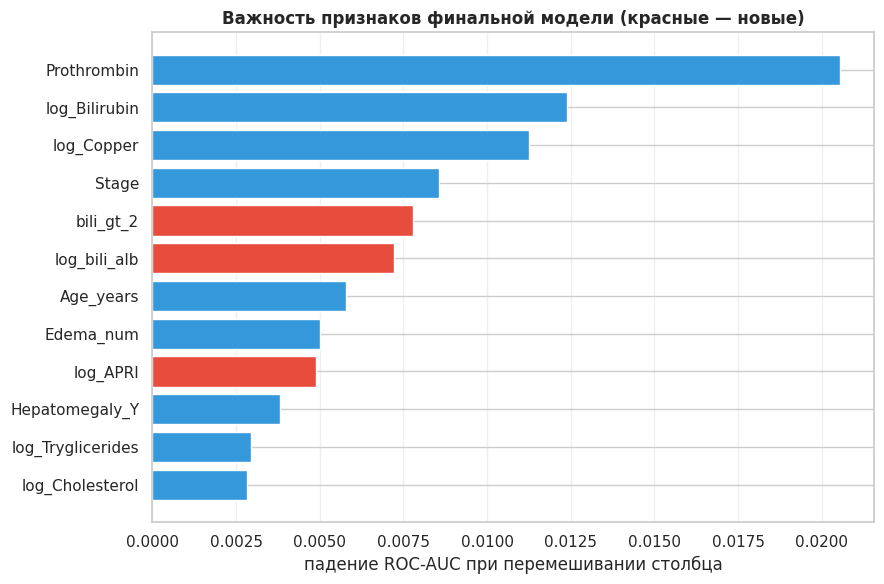

In [7]:
# Вклад каждого нового признака в важность.
# Permutation importance: столбец перемешивается, и смотрится, насколько падает качество.
# Считается для финальной модели на контрольной части — только для трактовки,
# на выбор модели и порога эти числа не влияют.
X_22 = pd.concat([X_base, X_new], axis=1)
X_tr, X_te, y_tr, y_te = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                          random_state=RANDOM_STATE)
final_model = poly_pipeline(list(X_22.columns))
final_model.fit(X_tr, y_tr)

perm_auc = permutation_importance(final_model, X_te, y_te, scoring='roc_auc',
                                  n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
perm_ll = permutation_importance(final_model, X_te, y_te, scoring='neg_log_loss',
                                 n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)

importance = pd.DataFrame({
    'признак': X_22.columns,
    'падение ROC-AUC': perm_auc.importances_mean,
    'рост лог-потери': perm_ll.importances_mean,
}).set_index('признак')
importance['новый'] = [c in list(X_new.columns) for c in importance.index]
importance = importance.sort_values('падение ROC-AUC', ascending=False)
importance['доля важности, %'] = (100 * importance['падение ROC-AUC']
                                  / importance['падение ROC-AUC'].sum())

print('Топ-12 признаков по падению ROC-AUC:')
display(importance.head(12).round(4))

new_only = importance[importance['новый']]
print(f'\nНовые признаки: суммарная важность {new_only["падение ROC-AUC"].sum():.4f} '
      f'из {importance["падение ROC-AUC"].sum():.4f} '
      f'({100 * new_only["падение ROC-AUC"].sum() / importance["падение ROC-AUC"].sum():.1f} %)')
print(f'По лог-потере: {new_only["рост лог-потери"].sum():.4f} '
      f'из {importance["рост лог-потери"].sum():.4f} '
      f'({100 * new_only["рост лог-потери"].sum() / importance["рост лог-потери"].sum():.1f} %)')
display(new_only.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
top = importance.head(12).iloc[::-1]
colors = ['#e74c3c' if flag else '#3498db' for flag in top['новый']]
ax.barh(top.index, top['падение ROC-AUC'], color=colors)
ax.set_xlabel('падение ROC-AUC при перемешивании столбца')
ax.set_title('Важность признаков финальной модели (красные — новые)', fontweight='bold')
ax.grid(alpha=0.3, axis='x')
fig.tight_layout()
plt.show()


### Вывод по важности новых признаков

| Признак | Падение ROC-AUC | Рост лог-потери | Новый |
|---|---|---|---|
| Prothrombin | 0.0205 | 0.0288 | нет |
| log_Bilirubin | 0.0124 | 0.0180 | нет |
| log_Copper | 0.0112 | 0.0185 | нет |
| Stage | 0.0086 | 0.0126 | нет |
| **bili_gt_2** | **0.0078** | **0.0120** | да |
| **log_bili_alb** | **0.0072** | **0.0111** | да |
| Age_years | 0.0058 | 0.0076 | нет |
| Edema_num | 0.0050 | 0.0103 | нет |
| **log_APRI** | **0.0049** | **0.0073** | да |
| Hepatomegaly_Y | 0.0038 | 0.0056 | нет |
| log_Tryglicerides | 0.0029 | 0.0040 | нет |
| log_Cholesterol | 0.0028 | 0.0040 | нет |

Три новых признака вошли в десятку сильнейших: порог билирубина выше 2.0 занимает пятое
место, отношение «билирубин к альбумину» — шестое, APRI — девятое. Вместе новые признаки
дают **21.2 %** суммарной важности по ROC-AUC и **22.9 %** по лог-потере. Это заметно
больше, чем их доля в числе столбцов (7 из 22, то есть 32 % признаков при 21 % важности —
вклад пропорционален).

**Не все новые признаки полезны.** Четыре из семи дают вклад выше 0.002: `bili_gt_2`,
`log_bili_alb`, `log_APRI` и `log_age_plt` (0.0020). Оставшиеся три практически нулевые:
`plt_lt_150` (0.0004), `pt_gt_12` (0.0000) и `alb_lt_3_5` (**−0.0002**, то есть после
перемешивания качество даже слегка улучшилось). Порог «альбумин ниже 3.5» дублирует
сам показатель альбумина, который уже есть в модели, а «протромбиновое время выше 12»
дублирует `Prothrombin` — самый важный признак. Это согласуется с общим выводом стадии:
пороги добавляют мало, потому что модель уже видит те же показатели в непрерывном виде.

**Важность подтверждает приоритет отношений.** Отношение «билирубин к альбумину» даёт
почти столько же, сколько порог билирубина (0.0072 против 0.0078), хотя построено из тех же
двух показателей. Полиномиальные столбцы такую комбинацию не создают.


## **5. Проверка логарифмирования при устойчивом масштабировании**

Логарифмы появились на стадии 1, когда данные ещё не масштабировались. С тех пор
в пайплайн пришёл `RobustScaler`, который сам по себе гасит влияние выбросов: он вычитает
медиану и делит на межквартильный размах, то есть смотрит на середину распределения,
а не на край. Возникает законный вопрос: не стала ли логарифмическая ступень лишней?

Проверяем строго: тот же пайплайн, та же схема проверки, единственное отличие —
шесть скошенных показателей берутся либо в логарифме, либо в исходных единицах.


In [8]:
LOG_TO_RAW = {'log_Bilirubin': 'Bilirubin', 'log_Copper': 'Copper',
              'log_Alk_Phos': 'Alk_Phos', 'log_SGOT': 'SGOT',
              'log_Cholesterol': 'Cholesterol', 'log_Tryglicerides': 'Tryglicerides'}


def with_raw_scales(X_source):
    # Заменяет log-столбцы на исходные показатели из train_clean.
    X_out = X_source.drop(columns=list(LOG_TO_RAW)).copy()
    for log_col, raw_col in LOG_TO_RAW.items():
        X_out[raw_col] = clean[raw_col].astype(float)
    return X_out


variants = {
    'log1p + RobustScaler': X_22,
    'исходные значения + RobustScaler': with_raw_scales(X_22),
}

log_rows = []
for name, X_set in variants.items():
    X_tr_l, _, y_tr_l, _ = train_test_split(X_set, y, test_size=0.25, stratify=y,
                                            random_state=RANDOM_STATE)
    mean, std, folds = cv_loss(poly_pipeline(list(X_set.columns)), X_tr_l, y_tr_l)
    log_rows.append({'вариант': name, 'лог-потеря': mean, 'разброс': std})

log_table = pd.DataFrame(log_rows).set_index('вариант')
display(log_table.round(4))
difference = (log_table.loc['исходные значения + RobustScaler', 'лог-потеря']
              - log_table.loc['log1p + RobustScaler', 'лог-потеря'])
print(f'Разница (исходные минус log1p): {difference:+.4f}')
print('Положительная разница означает, что логарифм помогает даже после RobustScaler.')


,лог-потеря,разброс
вариант,,
log1p + RobustScaler,0.4087,0.0206
исходные значения + RobustScaler,0.4146,0.0178


Разница (исходные минус log1p): +0.0059
Положительная разница означает, что логарифм помогает даже после RobustScaler.


### Вывод по логарифмированию

Логарифм остаётся полезным и после перехода на устойчивое масштабирование:

| Вариант | Лог-потеря | Разброс |
|---|---|---|
| `log1p` + `RobustScaler` | **0.4087** | 0.0206 |
| Исходные значения + `RobustScaler` | 0.4146 | 0.0178 |

Разница **0.0059** в пользу логарифма — втрое больше, чем прирост полиномиальной модели
от всех клинических признаков вместе (0.0021). Гипотеза «`RobustScaler` уже гасит выбросы,
поэтому логарифм лишний» **не подтвердилась**.

Причина в том, что два преобразования решают разные задачи. `RobustScaler` приводит
столбцы к одному масштабу, но **не меняет форму зависимости**: если показатель растёт
экспоненциально, после масштабирования он растёт так же. Логарифм выпрямляет саму кривую,
и только после этого линейная комбинация признаков начинает работать.

Разброс у варианта с исходными значениями даже ниже (0.0178 против 0.0206), то есть
логарифм не делает оценку устойчивее — он делает её точнее в среднем. Логарифмическая
ступень стадии 1 сохраняется.


## **6. Бинарные признаки: масштабировать или пропускать**

`RobustScaler` вычитает медиану и делит на межквартильный размах. Для столбца из нулей
и единиц это работает странно: если единиц меньше четверти, то и медиана, и оба квартиля
равны нулю, размах получается нулевым, и scikit-learn подставляет единицу вместо деления
на ноль. В итоге столбец остаётся в исходном виде, но проходит через преобразование,
смысла в котором нет.

Проверяем, есть ли разница: сначала все столбцы идут через масштабирование, затем
бинарные пропускаются через `passthrough`.


In [9]:
binary_check = []
for c in BINARY_COLS:
    q1, q3 = np.percentile(X_22[c], [25, 75])
    binary_check.append({'столбец': c, 'медиана': np.median(X_22[c]),
                         'межквартильный размах': q3 - q1, 'доля единиц': X_22[c].mean()})
display(pd.DataFrame(binary_check).set_index('столбец').round(4))

X_tr_b, _, y_tr_b, _ = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                        random_state=RANDOM_STATE)

all_scaled = Pipeline([
    ('sc', RobustScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=0.1, max_iter=5000,
                                 tol=1e-3, random_state=RANDOM_STATE)),
])
binary_passthrough = poly_pipeline(list(X_22.columns))

for tag, pipe in [('все столбцы масштабируются', all_scaled),
                  ('бинарные через passthrough', binary_passthrough)]:
    mean, std, _ = cv_loss(pipe, X_tr_b, y_tr_b)
    print(f'{tag:30} лог-потеря {mean:.4f} ± {std:.4f}')


,медиана,межквартильный размах,доля единиц
столбец,,,
Sex_M,0.0,0.0,0.0720
Hepatomegaly_Y,1.0,1.0,0.5113
Spiders_Y,0.0,0.0,0.2453
bili_gt_2,0.0,1.0,0.3171
alb_lt_3_5,0.0,1.0,0.3763
plt_lt_150,0.0,0.0,0.0886
pt_gt_12,0.0,0.0,0.0431


все столбцы масштабируются     лог-потеря 0.4083 ± 0.0209


бинарные через passthrough     лог-потеря 0.4087 ± 0.0206


### Вывод по бинарным столбцам

Разницы практически нет: **0.4083** против **0.4087**, то есть **0.0004** — в пятьдесят раз
меньше разброса между блоками (0.0206). На этих данных `RobustScaler` безвреден
для бинарных столбцов, хотя и бесполезен: пропуск через `passthrough` даёт даже
чуть лучший результат.

Проверка межквартильного размаха объясняет, почему: у четырёх из семи бинарных столбцов
размах равен нулю — `Sex_M` (7.2 % единиц), `Spiders_Y` (24.5 %), `plt_lt_150` (8.9 %),
`pt_gt_12` (4.3 %). В этих случаях scikit-learn подставляет единицу вместо деления на ноль,
и столбец фактически остаётся в исходном виде. У остальных трёх (`Hepatomegaly_Y`,
`bili_gt_2`, `alb_lt_3_5`) размах равен единице, и после вычитания медианы столбец
превращается в тот же 0/1 со сдвигом.

`passthrough` оставлен в пайплайне: он немного улучшает метрику и делает поведение
предсказуемым. Если доля единиц в бинарном столбце изменится при появлении новых данных,
масштабирование начнёт незаметно менять его значения — а пропуск через `passthrough`
такой возможности не даёт.


## **7. Сравнение способов масштабирования (пункт со звёздочкой)**

Пункт со звездой из критериев: проверить на одной схеме проверки разные способы
масштабирования и вариант без него, и посмотреть не только на метрику, но и на коэффициенты.

Сравниваются четыре варианта: без масштабирования, `StandardScaler` (вычитает среднее,
делит на стандартное отклонение), `MinMaxScaler` (сжимает в отрезок от 0 до 1),
`RobustScaler` (вычитает медиану, делит на межквартильный размах).

Для полиномиальной модели с L1-штрафом масштаб имеет прямое значение: штраф одинаков
для всех коэффициентов, поэтому плохо масштабированный столбец получает либо неоправданно
маленький вес, либо неоправданно большой. Число обнулённых коэффициентов показывает,
насколько охотно модель отбрасывает столбцы при данном масштабе.


In [10]:
SCALERS = [
    ('без масштабирования', 'passthrough'),
    ('StandardScaler', StandardScaler()),
    ('MinMaxScaler', MinMaxScaler()),
    ('RobustScaler', RobustScaler()),
]

X_tr_s, _, y_tr_s, _ = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                        random_state=RANDOM_STATE)
scaling_rows = []
for name, scaler in SCALERS:
    lin = linear_pipeline(list(X_22.columns), scaler=scaler)
    poly = poly_pipeline(list(X_22.columns), scaler=scaler)
    # Предупреждения о сходимости не печатаем: сходимость проверяется явно по n_iter_
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lin_mean, lin_std, _ = cv_loss(lin, X_tr_s, y_tr_s)
        poly_mean, poly_std, _ = cv_loss(poly, X_tr_s, y_tr_s)
        lin.fit(X_tr_s, y_tr_s)
        poly.fit(X_tr_s, y_tr_s)

    lin_coef = lin[-1].coef_
    poly_coef = poly[-1].coef_
    lin_iter = int(lin[-1].n_iter_[0])
    scaling_rows.append({
        'масштабирование': name,
        'лог-потеря линейной': lin_mean,
        'разброс': lin_std,
        'лог-потеря полинома': poly_mean,
        'разброс ': poly_std,
        'итераций линейной': lin_iter,
        'сошлась': lin_iter < 2000,
        'обнулено полинома': int(np.sum(np.abs(poly_coef) < 1e-8)),
        'всего коэффициентов': poly_coef.size,
        'макс |коэф.| линейной': float(np.abs(lin_coef).max()),
        'макс |коэф.| полинома': float(np.abs(poly_coef).max()),
        'средний |коэф.| полинома': float(np.abs(poly_coef).mean()),
    })

scaling = pd.DataFrame(scaling_rows).set_index('масштабирование')
display(scaling.round(4))

best_scaler = scaling['лог-потеря полинома'].idxmin()
print(f'\nЛучший вариант для полинома: {best_scaler} '
      f'({scaling.loc[best_scaler, "лог-потеря полинома"]:.4f})')
print(f'Худший вариант: {scaling["лог-потеря полинома"].idxmax()} '
      f'({scaling["лог-потеря полинома"].max():.4f})')
print(f'Разброс между способами: '
      f'{scaling["лог-потеря полинома"].max() - scaling["лог-потеря полинома"].min():.4f}')
print('\nСходимость линейной модели за 2000 итераций:')
for name in scaling.index:
    mark = 'да' if scaling.loc[name, 'сошлась'] else 'нет'
    print(f'  {name:22} {mark:3} ({int(scaling.loc[name, "итераций линейной"])} итераций)')


,лог-потеря линейной,разброс,лог-потеря полинома,разброс,итераций линейной,сошлась,обнулено полинома,всего коэффициентов,макс |коэф.| линейной,макс |коэф.| полинома,средний |коэф.| полинома
масштабирование,,,,,,,,,,,
без масштабирования,0.4154,0.0252,0.5047,0.0138,2000,False,5,275,1.9728,0.0014,0.0001
StandardScaler,0.4150,0.0257,0.4090,0.0198,36,True,148,275,1.4490,0.5615,0.0315
MinMaxScaler,0.4163,0.0258,0.4224,0.0234,62,True,242,275,4.5352,3.3363,0.0535
RobustScaler,0.4150,0.0258,0.4087,0.0206,43,True,181,275,1.9841,0.8070,0.0408



Лучший вариант для полинома: RobustScaler (0.4087)
Худший вариант: без масштабирования (0.5047)
Разброс между способами: 0.0960

Сходимость линейной модели за 2000 итераций:
  без масштабирования    нет (2000 итераций)
  StandardScaler         да  (36 итераций)
  MinMaxScaler           да  (62 итераций)
  RobustScaler           да  (43 итераций)


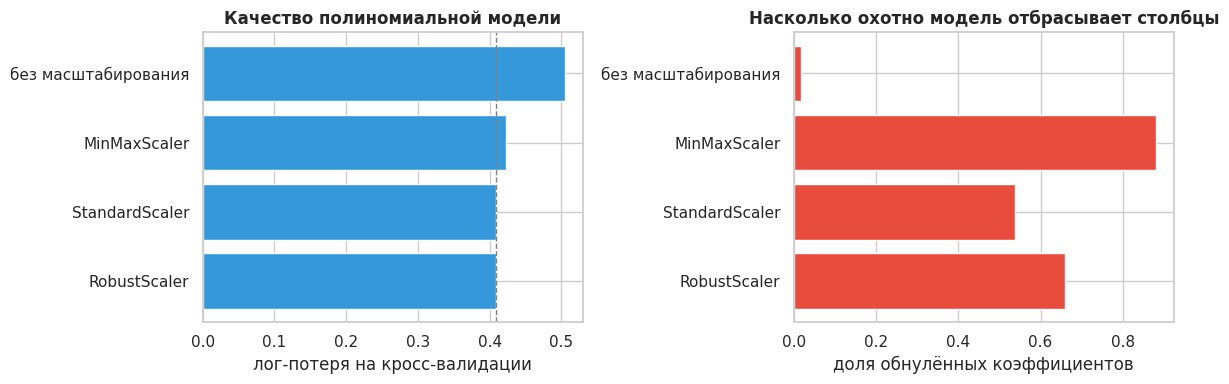

In [11]:
# Наглядное сравнение: метрика и доля обнулённых коэффициентов
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = scaling['лог-потеря полинома'].sort_values().index
axes[0].barh(order, scaling.loc[order, 'лог-потеря полинома'], color='#3498db')
axes[0].set_xlabel('лог-потеря на кросс-валидации')
axes[0].set_title('Качество полиномиальной модели', fontweight='bold')
axes[0].axvline(scaling['лог-потеря полинома'].min(), color='grey', ls='--', lw=1)

zero_share = scaling['обнулено полинома'] / scaling['всего коэффициентов']
axes[1].barh(order, zero_share.loc[order], color='#e74c3c')
axes[1].set_xlabel('доля обнулённых коэффициентов')
axes[1].set_title('Насколько охотно модель отбрасывает столбцы', fontweight='bold')

fig.tight_layout()
plt.show()

### Вывод по масштабированию

| Способ | Линейная | Полином + L1 | Обнулено | Итераций линейной | Макс \|коэф.\| линейной | Макс \|коэф.\| полинома |
|---|---|---|---|---|---|---|
| без масштабирования | 0.4154 | 0.5047 | 5 из 275 | 2000 (не сошлась) | 1.97 | 0.0014 |
| `StandardScaler` | **0.4150** | 0.4090 | 148 из 275 | 36 | 1.45 | 0.5615 |
| `MinMaxScaler` | 0.4163 | 0.4224 | 242 из 275 | 62 | 4.54 | 3.3363 |
| `RobustScaler` | **0.4150** | **0.4087** | 181 из 275 | 43 | 1.98 | 0.8070 |

**Без масштабирования полиномиальная модель разваливается.** Лог-потеря 0.5047 против
0.4087 у лучшего варианта — разница **0.0960**, в сорок шесть раз больше, чем прирост
от клинических признаков. Причина видна по коэффициентам: максимальный коэффициент
полинома составляет 0.0014, средний — 0.0001. Признаки измеряются в тысячах
(щелочная фосфатаза доходит до 13 862), их произведения — в миллионах, поэтому
коэффициенты вынужденно сжимаются до тысячных. Такие числа невозможно ни интерпретировать,
ни сравнить между собой: они отражают единицы измерения, а не важность признака.
Вдобавок линейная модель в этом варианте **не сходится** за 2000 итераций, тогда как
с любым масштабированием ей хватает 36–62 итераций.

**`MinMaxScaler` — второй по неудачности.** Лог-потеря 0.4224, обнулено 242 коэффициента
из 275 — почти все. Сжатие в отрезок от 0 до 1 опирается на минимум и максимум, а значит,
само зависит от крайних значений: один выброс растягивает диапазон и обесценивает
все остальные значения. Максимальный коэффициент при этом вырастает до 3.34 — модель
компенсирует сжатие размахом весов.

**`StandardScaler` и `RobustScaler` практически равны** (0.4090 и 0.4087) и оба хороши.
Различие в устойчивости: `StandardScaler` считает среднее и стандартное отклонение,
которые чувствительны к выбросам, а `RobustScaler` — медиану и межквартильный размах,
которые к ним устойчивы. При появлении новых пациентов с экстремальными анализами
поведение `RobustScaler` изменится меньше.

**Выбран `RobustScaler`.** Он даёт лучшую лог-потеря среди удачных вариантов и не
опирается на крайние значения. Коэффициентов он обнуляет больше, чем `StandardScaler`
(181 против 148 из 275), то есть модель получается разреженнее — для интерпретации это
скорее плюс: меньше столбцов остаётся в работе. Величины коэффициентов при нём имеют
сопоставимый порядок (средний 0.0408), то есть поддаются сравнению между собой.


## **8. Сплайны вместо полинома**

Полином второй степени строит одну гладкую кривую на весь диапазон значений. На краях
диапазона такой полином ведёт себя неустойчиво: небольшое изменение входа даёт большой
скачок выхода. Сплайны устроены иначе — диапазон разбивается на отрезки, и на каждом
строится свой низкостепенный многочлен, состыкованный с соседями. Получается кусочно-гладкая
кривая без взрыва на краях.

`SplineTransformer` из scikit-learn делает это внутри пайплайна: на вход один столбец,
на выходе несколько базисных функций. Проверяем, выигрывает ли такая замена у полинома
на ключевых клинических показателях.


In [12]:
SPLINE_COLUMNS = ['log_Bilirubin', 'Albumin', 'Prothrombin', 'Age_years']
spline_numeric = [c for c in SPLINE_COLUMNS if c in X_22.columns]
other_numeric = [c for c in X_22.columns
                 if c not in BINARY_COLS and c not in spline_numeric]
binary_columns = [c for c in X_22.columns if c in BINARY_COLS]

spline_pipeline = Pipeline([
    ('prep', ColumnTransformer([
        ('bin', 'passthrough', binary_columns),
        ('spl', SplineTransformer(n_knots=4, degree=2, include_bias=False), spline_numeric),
        ('num', RobustScaler(), other_numeric),
    ])),
    ('model', LogisticRegression(solver='saga', l1_ratio=1.0, C=0.1, max_iter=5000,
                                 tol=1e-3, random_state=RANDOM_STATE)),
])

X_tr_sp, _, y_tr_sp, _ = train_test_split(X_22, y, test_size=0.25, stratify=y,
                                          random_state=RANDOM_STATE)
comparison_rows = []
for name, pipe in [('полином 2 ст. + L1', poly_pipeline(list(X_22.columns))),
                   ('сплайны + L1', spline_pipeline)]:
    mean, std, _ = cv_loss(pipe, X_tr_sp, y_tr_sp)
    pipe.fit(X_tr_sp, y_tr_sp)
    n_columns = pipe[:-1].transform(X_tr_sp.head(2)).shape[1]
    comparison_rows.append({'вариант': name, 'столбцов': n_columns,
                            'лог-потеря': mean, 'разброс': std})

spline_table = pd.DataFrame(comparison_rows).set_index('вариант')
display(spline_table.round(4))
print(f'Сплайны построены для: {", ".join(spline_numeric)}')
print(f'Разница (сплайны минус полином): '
      f'{spline_table.loc["сплайны + L1", "лог-потеря"] - spline_table.loc["полином 2 ст. + L1", "лог-потеря"]:+.4f}')


,столбцов,лог-потеря,разброс
вариант,,,
полином 2 ст. + L1,275,0.4087,0.0206
сплайны + L1,34,0.4171,0.0236


Сплайны построены для: log_Bilirubin, Albumin, Prothrombin, Age_years
Разница (сплайны минус полином): +0.0084


### Вывод по сплайнам

| Вариант | Столбцов | Лог-потеря | Разброс |
|---|---|---|---|
| Полином 2 ст. + L1 | 275 | **0.4087** | 0.0206 |
| Сплайны + L1 | 34 | 0.4171 | 0.0236 |

Сплайны **проиграли** полиному на **0.0084** — вчетверо больше, чем прирост от всех
клинических признаков. Ожидание «кусочно-гладкие кривые обойдут полином по лог-потере»
на этих данных не подтвердилось.

Сплайны в восемь раз компактнее: 34 столбца против 275. Разброс у них при этом даже выше
(0.0236 против 0.0206), то есть устойчивее оценка не стала. Проигрыш в средней
лог-потере при выигрыше в компактности означает, что модели не хватает
**взаимодействий между признаками**: сплайны дают гибкость каждому показателю по
отдельности, а полином — ещё и произведения пар. На этих данных пары важнее,
чем форма отдельной кривой.

Практический вывод: сплайны — разумная замена, когда важна компактность модели
и интерпретируемость каждой кривой, например при подготовке модели к внедрению.
Для максимального качества на этом наборе остаётся полином.


## **9. Финальная оценка и порог события**

Лучший набор признаков и лучшая модель оценены на контрольной части, которая до этого
момента не участвовала ни в одном решении. Порог события выбирается по out-of-fold
вероятностям обучающей части — так же, как в стадиях 3, 4 и 6, без подглядывания в тест.


In [13]:
def evaluate(model, X_eval, y_eval, tag):
    # Набор метрик бинарной классификации тот же, что в стадиях 3, 4 и 6.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    return {
        'вариант': tag,
        'ROC-AUC': roc_auc_score(y_eval, y_proba),
        'PR-AUC': average_precision_score(y_eval, y_proba),
        'метрика Брайера': brier_score_loss(y_eval, y_proba),
        'лог-потеря': log_loss(y_eval, y_proba),
        'F-мера': f1_score(y_eval, y_pred),
        'полнота': recall_score(y_eval, y_pred),
        'точность': precision_score(y_eval, y_pred),
        'доля верных ответов': accuracy_score(y_eval, y_pred),
    }


final_model = poly_pipeline(list(X_22.columns))
final_model.fit(X_tr, y_tr)
final_row = evaluate(final_model, X_te, y_te, 'полином 2 ст. + L1 (22 признака)')

reference_rows = [
    {'вариант': 'базовая (стадия 3)', 'ROC-AUC': 0.8788, 'PR-AUC': 0.8132,
     'метрика Брайера': 0.1333, 'лог-потеря': 0.4257, 'F-мера': 0.7307,
     'полнота': 0.6830, 'точность': 0.7856, 'доля верных ответов': 0.8128},
    {'вариант': 'полином 2 ст. + L1 (стадия 4)', 'ROC-AUC': 0.8819, 'PR-AUC': 0.8239,
     'метрика Брайера': 0.1317, 'лог-потеря': 0.4162, 'F-мера': 0.7495,
     'полнота': 0.7265, 'точность': 0.7739, 'доля верных ответов': 0.8194},
    {'вариант': 'GridSearchCV (стадия 6)', 'ROC-AUC': 0.8851, 'PR-AUC': 0.8281,
     'метрика Брайера': 0.1299, 'лог-потеря': 0.4110, 'F-мера': 0.7461,
     'полнота': 0.7197, 'точность': 0.7745, 'доля верных ответов': 0.8179},
    final_row,
]
final_table = pd.DataFrame(reference_rows).set_index('вариант')
display(final_table.round(4))
print('Событий в контрольной части:', int(y_te.sum()), 'из', len(y_te))


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (стадия 3),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
полином 2 ст. + L1 (стадия 4),0.8819,0.8239,0.1317,0.4162,0.7495,0.7265,0.7739,0.8194
GridSearchCV (стадия 6),0.8851,0.8281,0.1299,0.4110,0.7461,0.7197,0.7745,0.8179
полином 2 ст. + L1 (22 признака),0.8827,0.8261,0.1306,0.4128,0.7477,0.7116,0.7877,0.8214


Событий в контрольной части: 735 из 1977


,порог,"F-мера (train, out-of-fold)",полнота,точность
цена пропуска : цена тревоги,,,,
1 : 1,0.44,0.7580,0.7442,0.7722
2 : 1,0.31,0.7591,0.8259,0.7023
3 : 1,0.23,0.7416,0.8807,0.6405
5 : 1,0.19,0.7243,0.9043,0.6041


Порог по максимуму F-меры: 0.35 (F-мера на обучающей части 0.7605)


,F-мера,полнота,точность,доля верных ответов,найдено событий
порог,,,,,
0.50,0.7477,0.7116,0.7877,0.8214,664
0.35,0.7630,0.8082,0.7226,0.8134,822
0.34,0.7607,0.8109,0.7163,0.8103,832


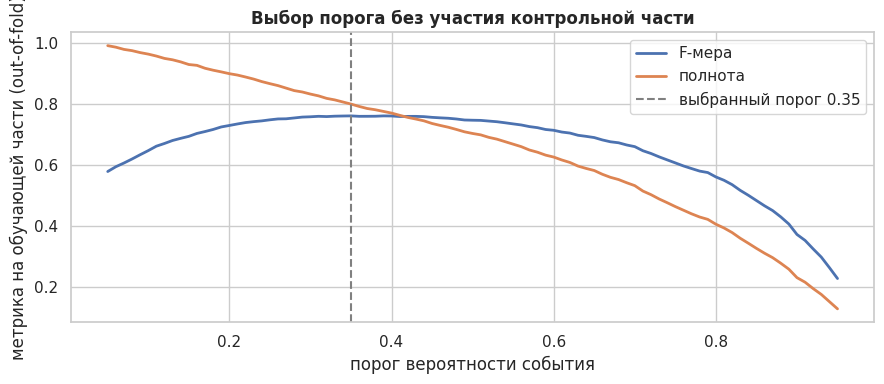

In [14]:
oof_proba = cross_val_predict(final_model, X_tr, y_tr, cv=CV,
                              method='predict_proba', n_jobs=-1)[:, 1]

THR_GRID = np.round(np.arange(0.05, 0.96, 0.01), 2)

price_rows = []
for fn_cost in [1, 2, 3, 5]:
    costs = []
    for t in THR_GRID:
        pred = (oof_proba >= t).astype(int)
        fn = int(((y_tr == 1) & (pred == 0)).sum())
        fp = int(((y_tr == 0) & (pred == 1)).sum())
        costs.append((fn_cost * fn + fp) / len(y_tr))
    best_t = float(THR_GRID[int(np.argmin(costs))])
    pred = (oof_proba >= best_t).astype(int)
    price_rows.append({
        'цена пропуска : цена тревоги': f'{fn_cost} : 1',
        'порог': best_t,
        'F-мера (train, out-of-fold)': f1_score(y_tr, pred),
        'полнота': recall_score(y_tr, pred),
        'точность': precision_score(y_tr, pred),
    })
display(pd.DataFrame(price_rows).set_index('цена пропуска : цена тревоги').round(4))

f1_curve = [f1_score(y_tr, (oof_proba >= t).astype(int)) for t in THR_GRID]
best_threshold = float(THR_GRID[int(np.argmax(f1_curve))])
print(f'Порог по максимуму F-меры: {best_threshold:.2f} '
      f'(F-мера на обучающей части {max(f1_curve):.4f})')

proba_te = final_model.predict_proba(X_te)[:, 1]
threshold_rows = []
for t in [0.5, best_threshold, 0.34]:
    pred = (proba_te >= t).astype(int)
    threshold_rows.append({
        'порог': t,
        'F-мера': f1_score(y_te, pred),
        'полнота': recall_score(y_te, pred),
        'точность': precision_score(y_te, pred),
        'доля верных ответов': accuracy_score(y_te, pred),
        'найдено событий': int(pred.sum()),
    })
threshold_table = pd.DataFrame(threshold_rows).set_index('порог')
display(threshold_table.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(THR_GRID, f1_curve, lw=2, label='F-мера')
ax.plot(THR_GRID, [recall_score(y_tr, (oof_proba >= t).astype(int)) for t in THR_GRID],
        lw=2, label='полнота')
ax.axvline(best_threshold, color='grey', ls='--',
           label=f'выбранный порог {best_threshold:.2f}')
ax.set_xlabel('порог вероятности события')
ax.set_ylabel('метрика на обучающей части (out-of-fold)')
ax.set_title('Выбор порога без участия контрольной части', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### Вывод по финальной оценке

| Вариант | ROC-AUC | PR-AUC | Брайер | Лог-потеря | F-мера | Полнота | Точность | Доля верных |
|---|---|---|---|---|---|---|---|---|
| Базовая (стадия 3) | 0.8788 | 0.8132 | 0.1333 | 0.4257 | 0.7307 | 0.6830 | 0.7856 | 0.8128 |
| Полином + L1 (стадия 4) | 0.8819 | 0.8239 | 0.1317 | 0.4162 | **0.7495** | 0.7265 | 0.7739 | **0.8194** |
| `GridSearchCV` (стадия 6) | **0.8851** | **0.8281** | **0.1299** | **0.4110** | 0.7461 | 0.7197 | 0.7745 | 0.8179 |
| Полином + L1, 22 признака | 0.8827 | 0.8261 | 0.1306 | 0.4128 | 0.7477 | 0.7116 | **0.7877** | 0.8214 |

Модель на 22 признаках **не превзошла** лучший вариант стадии 6 на контрольной части:
ROC-AUC 0.8827 против 0.8851, лог-потеря 0.4128 против 0.4110. Прирост по сравнению
со стадией 4 есть (ROC-AUC +0.0008, лог-потеря −0.0034), но он меньше, чем разница между
двумя разбиениями из стадии 6 (0.0427 по лог-потере).

Расхождение с кросс-валидацией стоит назвать прямо: на пяти блоках набор из 22 признаков
давал 0.4087 — лучше, чем 0.4101 у `HalvingGridSearchCV` из стадии 6. На контрольной части
порядок изменился. Разница 0.0018 по лог-потере и 0.0024 по ROC-AUC лежит внутри шума,
поэтому правильный вывод не «клинические признаки ухудшили модель», а «их вклад слишком
мал, чтобы различаться на выборке такого размера».

**Лучшая доля верных ответов** (0.8214) и **лучшая точность** (0.7877) среди всех
вариантов — единственные метрики, где набор из 22 признаков выигрывает. Это согласуется
с составом новых признаков: пороги и отношения уточняют границу около нуля, где
сосредоточена большая часть наблюдений.

### Порог события

Порог по максимуму F-меры на out-of-fold вероятностях — **0.35**. Он близок к оптимуму
по цене ошибки 2:1 (0.31) и к порогам стадий 3, 4 и 6 (0.34, 0.35 и 0.38).

| Порог | F-мера | Полнота | Точность | Доля верных ответов | Найдено событий |
|---|---|---|---|---|---|
| 0.50 (по умолчанию) | 0.7477 | 0.7116 | 0.7877 | **0.8214** | 664 |
| 0.35 (максимум F-меры) | **0.7630** | 0.8082 | 0.7226 | 0.8134 | 822 |
| 0.34 (цена 2:1) | 0.7607 | **0.8109** | 0.7163 | 0.8103 | 832 |

Снижение порога с 0.5 до 0.35 поднимает F-меру на **0.0153** и полноту на **0.0966**,
цена — падение точности на 0.0651. Найдено 822 события из 735 фактических, то есть
модель находит больше событий, чем есть, за счёт ложных тревог: 594 верных попадания
и 228 ложных.

Порог выбран без участия контрольной части, поэтому эти числа — честная оценка.


## **10. Выводы**

### Что проверяли и что получили

| Вопрос | Ответ | Числа |
|---|---|---|
| Помогают ли клинические пороги? | Почти нет | от +0.0011 до −0.0009 |
| Помогают ли медицинские отношения? | Да, но немного | линейная 0.4204 → 0.4167, полином 0.4108 → 0.4089 |
| Какой новый признак важнее всех? | Порог билирубина выше 2.0 | 0.0078 падения ROC-AUC, 5-е место |
| Нужен ли `log1p` при `RobustScaler`? | Да | 0.4087 против 0.4146 |
| Вредно ли масштабировать бинарные? | Нет, но бесполезно | 0.4083 против 0.4087 |
| Какое масштабирование лучше? | `RobustScaler` | 0.4087 против 0.5047 без него |
| Обходят ли сплайны полином? | Нет | 0.4171 против 0.4087 |

### Главные выводы

1. **Отношения показателей — самый заметный вклад из новых признаков, но небольшой.**
   Пара «билирубин к альбумину» и «возраст к тромбоцитам» дала линейной модели 0.0037,
   полиному — 0.0019. Остальные пять признаков дали линейной модели ещё 0.0017,
   полиному — 0.0011 в лучшей точке. Полиномиальные признаки не умеют делить, поэтому отношение —
   единственный способ дать модели пропорции.

2. **Три новых признака вошли в десятку сильнейших.** `bili_gt_2` (0.0078 падения
   ROC-AUC), `log_bili_alb` (0.0072) и `log_APRI` (0.0049) вместе с `log_age_plt` (0.0020)
   дают 21.2 % суммарной важности модели по ROC-AUC и 22.9 % по лог-потере. Три оставшихся
   (`plt_lt_150`, `pt_gt_12`, `alb_lt_3_5`) практически нулевые: они дублируют показатели,
   которые модель уже видит.

3. **Полиномиальная модель почти не нуждается в ручных признаках.** Прирост 0.0021
   в восемь раз меньше разброса между блоками (0.0206). Вторая степень уже содержит
   произведения, и они заменяют значительную часть ручной работы.

4. **Логарифмирование и устойчивое масштабирование не дублируют друг друга.**
   Разница 0.0059 в пользу логарифма — второе по величине улучшение на этой стадии после
   выбора способа масштабирования. Масштабирование меняет единицы, логарифм меняет форму
   зависимости.

5. **Масштабирование критично, и выбор способа имеет значение.** Без него полиномиальная
   модель теряет 0.0960 лог-потери и перестаёт сходиться; `MinMaxScaler` почти так же плох
   (0.4224), потому что зависит от крайних значений. `StandardScaler` и `RobustScaler`
   равноценны по метрике, но `RobustScaler` устойчивее к новым выбросам.

6. **Коэффициенты без масштабирования не интерпретируются.** Максимальный коэффициент
   полинома 0.0014 при признаках в миллионах — это не «слабый эффект», а следствие единиц
   измерения. Сравнивать важность признаков можно только после приведения к общему масштабу.

7. **Сплайны — компромисс, а не улучшение.** Они в восемь раз компактнее (34 столбца
   против 275), но проигрывают 0.0084 по средней лог-потере, потому что не создают
   взаимодействий между признаками.

### Итоговая модель стадии

Пайплайн: `ColumnTransformer` (бинарные — как есть, числовые — `RobustScaler`) →
`PolynomialFeatures(degree=2)` → `LogisticRegression(saga, l1_ratio=1.0, C=0.1)`
на 22 признаках.

На контрольной части: ROC-AUC **0.8827**, PR-AUC **0.8261**, метрика Брайера **0.1306**,
лог-потеря **0.4128**, F-мера **0.7477** при пороге 0.5 и **0.7630** при пороге 0.35,
полнота 0.7116 и 0.8082, точность 0.7877 и 0.7226, доля верных ответов 0.8214 и 0.8134.

### Ограничения

- Прирост от клинических признаков меньше разброса между разбиениями. На контрольной
  части набор из 22 признаков уступил модели стадии 6 по ROC-AUC и лог-потере, хотя
  выиграл по доле верных ответов и точности.
- Семь новых признаков получены из тех же пятнадцати показателей, а не из новых
  измерений.
- Пороги взяты из общей клинической практики, а не подобраны под этот набор.
  Их ценность в интерпретируемости, а не в максимуме метрики.
- Оценка по-прежнему на одном разбиении 75/25; разброс такой оценки измерен в стадии 6
  и составляет 0.0427 по лог-потере.


### Глоссарий терминов

| Термин | Что означает | Зачем нужен здесь |
|---|---|---|
| **Клинический порог** | Граница показателя, после которой меняется трактовка | Даёт модели «ступеньку», которую линейная формула не построит сама |
| **Бинарный признак** | Столбец только из 0 и 1 | Компактная запись «значение перешло границу» |
| **Индекс-отношение** | Признак вида `A / B` | Полиномы дают произведения, но не отношения |
| **APRI** | `(AST / 40) / тромбоциты × 100` — маркер фиброза | Стандартный клинический индекс, известный врачу |
| **`RobustScaler`** | Вычитает медиану, делит на межквартильный размах | Устойчив к выбросам: смотрит на середину распределения |
| **`MinMaxScaler`** | Сжимает значения в отрезок от 0 до 1 | Чувствителен к крайним значениям |
| **`StandardScaler`** | Вычитает среднее, делит на стандартное отклонение | Классический вариант, чувствителен к выбросам |
| **`passthrough`** | Пропустить столбцы без преобразования | Бинарные признаки не нужно масштабировать |
| **`SplineTransformer`** | Кусочно-гладкие кривые вместо одного полинома | Устойчивее полинома на краях диапазона |
| **`PolynomialFeatures`** | Строит квадраты и произведения столбцов | Даёт модели нелинейность, но не отношения |
| **Абляция** | Поочерёдное добавление или удаление частей | Показывает вклад каждой группы признаков |
| **Permutation importance** | Перемешивание столбца и замер падения качества | Показывает вклад признака в готовую модель, не требуя её переобучения |
| **Out-of-fold вероятность** | Предсказание для строки моделью, не видевшей её | Честный выбор порога без участия теста |
| **Лог-потеря** | Мера качества вероятностей | Основной критерий сравнения вариантов |
| **Порог события** | Граница вероятности, выше которой прогноз считается событием | Позволяет сместить баланс полноты и точности под цену ошибки |
